# S5 - Pipeline batch de ETL distribuido: indicador U1 de heladas en Juliaca
**Proyecto Sello · Equipo 10 BIG IMPACT · Salcca Aquino, Nilver**

**Pregunta de U1:** ¿en qué meses (2010 – 01-Oct-2026) la mínima diaria es ≤ 0 °C en más del 30 % de los días, y qué tan bien se puede predecir la temperatura mínima de la noche con lo que se mide a las 18:00?

**Pipeline:** WeatherAPI (CSV) → Bronze → validación de calidad → Silver → Parquet particionado por mes (Gold) → dataset de una fila por noche → modelo de regresión comparado → modelo guardado.

Este notebook corre de principio a fin: **Kernel → Restart Kernel and Run All Cells**.

In [1]:
import time
T0 = time.time()

try:
    import matplotlib
except ImportError:
    %pip install -q matplotlib
    import matplotlib

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

print("matplotlib", matplotlib.__version__, "| pandas", pd.__version__)

matplotlib 3.10.9 | pandas 2.3.3


## 0. Configuración

In [2]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("sesion5-pipeline-u1-heladas")
    .master("local[*]")
    .config("spark.ui.port", "4040")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.driver.memory", "4g")
    .getOrCreate()
)

BRONZE = "/opt/u1/s01-arquitectura/data/historico"
GOLD = "/opt/u1/s05-evaluacion/artifacts/clima_particionado"
MODELO = "/opt/u1/s05-evaluacion/artifacts/modelo_rf_heladas"

print("Spark", spark.version)
print("Bronze:", BRONZE)
print("Gold:  ", GOLD)
print("Modelo:", MODELO)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/20 02:59:47 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/20 02:59:48 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.
26/11/20 02:59:48 WARN Utils: Service 'SparkUI' could not bind on port 4041. Attempting port 4042.
26/11/20 02:59:48 WARN Utils: Service 'SparkUI' could not bind on port 4042. Attempting port 4043.
26/11/20 02:59:48 WARN Utils: Service 'SparkUI' could not bind on port 4043. Attempting port 4044.


Spark 4.2.0
Bronze: /opt/u1/s01-arquitectura/data/historico
Gold:   /opt/u1/s05-evaluacion/artifacts/clima_particionado
Modelo: /opt/u1/s05-evaluacion/artifacts/modelo_rf_heladas


## 1. Arquitectura y visión general del pipeline

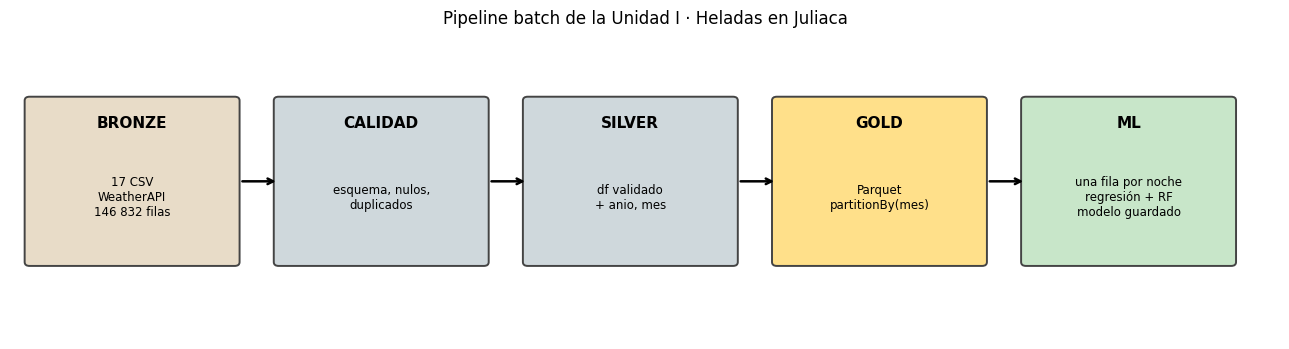

In [3]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(13, 3.6))
ax.set_xlim(0, 13); ax.set_ylim(0, 4); ax.axis("off")

bloques = [
    ("#e8dcc8", "BRONZE", "17 CSV\nWeatherAPI\n146 832 filas"),
    ("#cfd8dc", "CALIDAD", "esquema, nulos,\nduplicados"),
    ("#cfd8dc", "SILVER", "df validado\n+ anio, mes"),
    ("#ffe08a", "GOLD", "Parquet\npartitionBy(mes)"),
    ("#c8e6c9", "ML", "una fila por noche\nregresión + RF\nmodelo guardado"),
]
x = 0.2
for color, titulo, texto in bloques:
    ax.add_patch(FancyBboxPatch((x, 1.0), 2.1, 2.1, boxstyle="round,pad=0.05", fc=color, ec="#444", lw=1.4))
    ax.text(x + 1.05, 2.75, titulo, ha="center", fontsize=11, fontweight="bold")
    ax.text(x + 1.05, 1.85, texto, ha="center", va="center", fontsize=8.5)
    if titulo != "ML":
        ax.annotate("", xy=(x + 2.55, 2.05), xytext=(x + 2.15, 2.05), arrowprops=dict(arrowstyle="->", lw=1.8))
    x += 2.55

ax.set_title("Pipeline batch de la Unidad I · Heladas en Juliaca", fontsize=12)
plt.tight_layout()
plt.show()

## 2. Bronze: lectura con esquema explícito

In [4]:
from pyspark.sql.types import (StructType, StructField, StringType, TimestampType,
                               DoubleType, IntegerType)
from pyspark.sql import functions as F

schema_clima = StructType([
    StructField("ciudad",       StringType(),    True),
    StructField("hora",         TimestampType(), True),
    StructField("temperatura",  DoubleType(),    True),
    StructField("puntoRocio",   DoubleType(),    True),
    StructField("humedad",      IntegerType(),   True),
    StructField("nubosidad",    IntegerType(),   True),
    StructField("presion",      DoubleType(),    True),
    StructField("precipitacion",DoubleType(),    True),
])

df_bronze = spark.read.option("header", True).schema(schema_clima).csv(BRONZE)

# Control: las columnas obligatorias existen
requeridas = {"ciudad", "hora", "temperatura", "puntoRocio", "humedad", "nubosidad"}
assert requeridas.issubset(set(df_bronze.columns)), "Faltan columnas obligatorias"

n_bronze = df_bronze.count()
f_min, f_max = df_bronze.agg(F.min("hora"), F.max("hora")).first()
print(f"Bronze: {n_bronze:,} filas | rango {f_min} -> {f_max}")

# Control: la regla permanente, no hay datos posteriores al 1-oct-2026
assert f_max.strftime("%Y-%m-%d") <= "2026-10-01", "Hay datos posteriores al 1-oct-2026"

df_bronze.printSchema()

Bronze: 146,832 filas | rango 2010-01-01 00:00:00 -> 2026-10-01 23:00:00
root
 |-- ciudad: string (nullable = true)
 |-- hora: timestamp (nullable = true)
 |-- temperatura: double (nullable = true)
 |-- puntoRocio: double (nullable = true)
 |-- humedad: integer (nullable = true)
 |-- nubosidad: integer (nullable = true)
 |-- presion: double (nullable = true)
 |-- precipitacion: double (nullable = true)



## 3. Controles de calidad (con `assert`)
Se miden antes de limpiar: nulos por columna, duplicados por (ciudad, hora) y valores fuera de rango físico.

In [5]:
# 3.1 Nulos por columna
nulos = df_bronze.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df_bronze.columns]).first().asDict()

# 3.2 Duplicados por clave natural (ciudad, hora)
n_distintos = df_bronze.select("ciudad", "hora").distinct().count()
n_dups = n_bronze - n_distintos

# 3.3 Rangos físicos plausibles
fuera_temp = df_bronze.filter((F.col("temperatura") < -30) | (F.col("temperatura") > 40)).count()
fuera_hum  = df_bronze.filter((F.col("humedad") < 0) | (F.col("humedad") > 100)).count()

print("Nulos por columna:", nulos)
print("Duplicados (ciudad, hora):", n_dups)
print("Temperatura fuera de [-30, 40]:", fuera_temp)
print("Humedad fuera de [0, 100]:", fuera_hum)

# Asserts: si algo cambia en los datos, el notebook falla a la vista
assert nulos["ciudad"] == 0 and nulos["hora"] == 0 and nulos["temperatura"] == 0, "Nulos en columnas clave"
assert n_dups == 0, f"Hay {n_dups} duplicados"
assert fuera_temp == 0 and fuera_hum == 0, "Valores fuera de rango"
print("\nTodos los controles de calidad pasaron")

Nulos por columna: {'ciudad': 0, 'hora': 0, 'temperatura': 0, 'puntoRocio': 0, 'humedad': 0, 'nubosidad': 0, 'presion': 0, 'precipitacion': 0}
Duplicados (ciudad, hora): 0
Temperatura fuera de [-30, 40]: 0
Humedad fuera de [0, 100]: 0

Todos los controles de calidad pasaron


### 3.4 Evidencia gráfica de la calidad

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


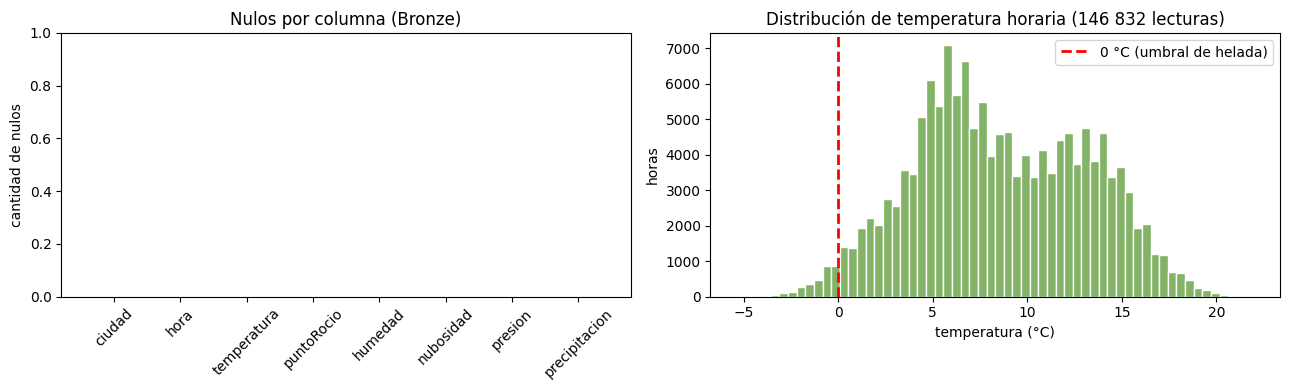

In [6]:
temps = df_bronze.select("temperatura").toPandas()["temperatura"]

fig, axs = plt.subplots(1, 2, figsize=(13, 4))

# Izquierda: nulos por columna
axs[0].bar(list(nulos.keys()), list(nulos.values()), color="#6c8ebf")
axs[0].set_title("Nulos por columna (Bronze)")
axs[0].set_ylabel("cantidad de nulos")
axs[0].tick_params(axis="x", rotation=45)
axs[0].set_ylim(0, max(1, max(nulos.values())))

# Derecha: distribución de temperatura con la línea de helada
axs[1].hist(temps, bins=60, color="#82b366", edgecolor="white")
axs[1].axvline(0, color="red", lw=2, ls="--", label="0 °C (umbral de helada)")
axs[1].set_title("Distribución de temperatura horaria (146 832 lecturas)")
axs[1].set_xlabel("temperatura (°C)")
axs[1].set_ylabel("horas")
axs[1].legend()

plt.tight_layout()
plt.show()

## 4. Silver: deduplicación determinista, nulos y columnas derivadas

Bronze 146,832 -> Silver 146,832  (descartadas: 0)
Silver validado


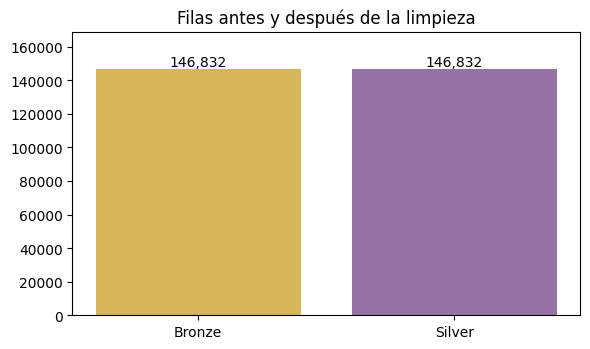

In [7]:
from pyspark.sql.window import Window

# Deduplicación determinista: ante una clave repetida, gana la fila con más información
w = Window.partitionBy("ciudad", "hora").orderBy(F.col("humedad").desc_nulls_last(),
                                                  F.col("temperatura").asc_nulls_last())
df_dedup = (df_bronze.withColumn("rn", F.row_number().over(w))
                      .filter("rn = 1").drop("rn"))

# Nulos: se descartan solo si falta una columna clave
df_silver = (df_dedup.na.drop(subset=["ciudad", "hora", "temperatura"])
                     .withColumn("anio", F.year("hora"))
                     .withColumn("mes",  F.month("hora")))

n_silver = df_silver.count()
print(f"Bronze {n_bronze:,} -> Silver {n_silver:,}  (descartadas: {n_bronze - n_silver:,})")

# Controles posteriores a la limpieza
assert df_silver.select("ciudad", "hora").distinct().count() == n_silver, "Silver conserva duplicados"
assert df_silver.filter(F.col("temperatura").isNull()).count() == 0, "Silver conserva nulos"
assert n_silver == n_bronze - n_dups, "El conteo de Silver no cuadra con Bronze menos duplicados"
print("Silver validado")

# Antes vs. después, en gráfico
fig, ax = plt.subplots(figsize=(6, 3.6))
barras = ax.bar(["Bronze", "Silver"], [n_bronze, n_silver], color=["#d6b656", "#9673a6"])
ax.bar_label(barras, fmt="{:,.0f}")
ax.set_title("Filas antes y después de la limpieza")
ax.set_ylim(0, n_bronze * 1.15)
plt.tight_layout()
plt.show()